<a href="https://colab.research.google.com/github/OjasRaj/Machine-Learning-Practice/blob/main/OPPE_1_Practice.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [4]:
import pandas as pd
import numpy as np
df=pd.read_csv("/content/data.csv")
df.head()

,customer_id,name,age,gender,email,join_date,last_purchase,total_spent,purchase_count,country,city,postal_code,subscription_type,credit_score,is_active,payment_method,preferred_category,avg_session_duration,device_type,campaign_response
0,4d623250-b704-4df8-aea2-5403458a1d6e,Sean Nelson,41,F,tylersmith@example.org,"Dec 19, 2020",2025-04-02,238.517142,51.0,Germany,Port Michaelmouth,06803,Corporate,663,True,NaN,Groceries,1066.626690,TABLET,NaN
1,e5593c2b-1ed8-4fe8-be82-acced82f9711,Eddie Wood,38,Female,xreed@example.net,30/10/2021,2024-12-25,93.126377,31.0,USA,Brig...,64245,NaN,656,N,PayPal,Clothing,327.762945,mobile,no
2,7240c499-1c3d-4188-8b12-76c515aff931,Abigail Graham,11,M,cartersara@example.com,"May 03, 2022",2025-05-10,873.017713,87.0,Germany,Port Kevinton,43574,Trial,672,N,Cryptocurrency,Clothing,95.654242,Mobile,No
3,43c7001d-4c6d-4011-aa02-e9b57c0e3944,Jessica Contreras,40,NaN,fsalazar@example.org,"Aug 03, 2021",NaN,401.703726,NaN,India,Gillespietown,NaN,Trial,614,True,PayPal,Home,498.371991,mobile,NaN
4,4fb0f886-7e67-4982-bfe0-959272cece1b,Kelly Olson,20,Female,robert21@example.org,"Apr 05, 2024",2025-05-07,1198.186419,34.0,Germany,jamesberg,82358,Premium,692,N,Bank Transfer,Groceries,NaN,mobile,YES


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 20 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   customer_id           10000 non-null  object 
 1   name                  9041 non-null   object 
 2   age                   10000 non-null  int64  
 3   gender                8620 non-null   object 
 4   email                 10000 non-null  object 
 5   join_date             10000 non-null  object 
 6   last_purchase         8470 non-null   object 
 7   total_spent           10000 non-null  float64
 8   purchase_count        9059 non-null   float64
 9   country               8433 non-null   object 
 10  city                  10000 non-null  object 
 11  postal_code           7523 non-null   object 
 12  subscription_type     7963 non-null   object 
 13  credit_score          10000 non-null  int64  
 14  is_active             10000 non-null  object 
 15  payment_method      

In [19]:
df.select_dtypes(["int","float"]).columns.tolist()

['age',
 'total_spent',
 'purchase_count',
 'credit_score',
 'avg_session_duration']

In [10]:
df.select_dtypes(exclude=object).shape

(10000, 5)

In [14]:
df['country'].unique()

array(['Germany', 'USA', 'India', nan, 'Canada', 'Australia', 'China',
       'France', 'Brazil', 'UK', 'Japan'], dtype=object)

In [26]:
df.isna().sum().sort_values(ascending=False)

,0
postal_code,2477
preferred_category,2125
subscription_type,2037
avg_session_duration,2023
campaign_response,1992
payment_method,1671
country,1567
last_purchase,1530
gender,1380
name,959


In [27]:
df.isna().sum().sum()

np.int64(18702)

In [31]:
df.T.isna().sum() #row wise via transpose

,0
0,2
1,1
2,0
3,5
4,1
...,...
9995,0
9996,2
9997,2
9998,2


In [34]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
age,10000.0,44.716800,14.853035,10.0,35.000000,45.000000,55.000000,99.000000
total_spent,10000.0,502.914509,287.149807,0.0,298.716718,497.856540,699.429102,1772.150969
purchase_count,9059.0,50.394525,29.039124,1.0,25.000000,51.000000,76.000000,100.000000
credit_score,10000.0,695.745000,93.981842,344.0,632.000000,697.000000,766.000000,850.000000
avg_session_duration,7977.0,602.395589,297.331131,0.0,396.683188,593.066471,802.223030,1803.425649


In [41]:
colu=df.select_dtypes("number").columns

In [44]:
corr_mat=df[colu].corr()
corr_mat

,age,total_spent,purchase_count,credit_score,avg_session_duration
age,1.000000,0.001655,-0.001769,0.006844,0.002468
total_spent,0.001655,1.000000,0.004251,-0.006518,-0.009668
purchase_count,-0.001769,0.004251,1.000000,-0.015247,0.019889
credit_score,0.006844,-0.006518,-0.015247,1.000000,-0.009221
avg_session_duration,0.002468,-0.009668,0.019889,-0.009221,1.000000


In [48]:
import seaborn as sns

<Axes: >

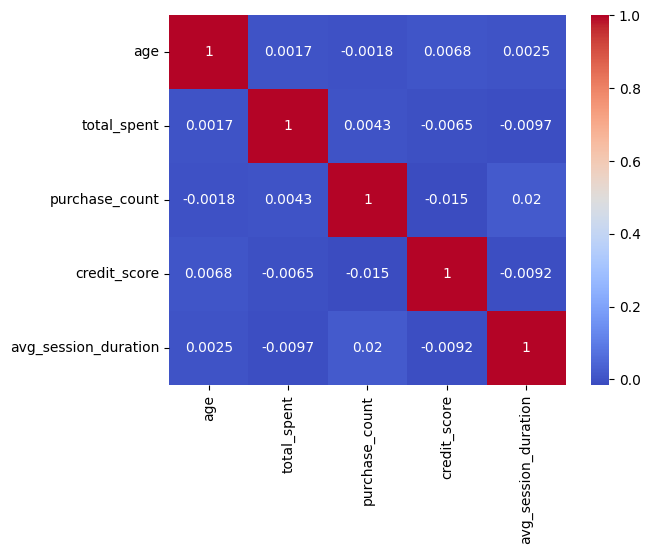

In [51]:
sns.heatmap(corr_mat,annot=True, cmap="coolwarm")

In [53]:
df.iloc[::2,1::2] #even indexed rows, odd indexed cols

,name,gender,join_date,total_spent,country,postal_code,credit_score,payment_method,avg_session_duration,campaign_response
0,Sean Nelson,F,"Dec 19, 2020",238.517142,Germany,06803,663,NaN,1066.626690,NaN
2,Abigail Graham,M,"May 03, 2022",873.017713,Germany,43574,672,Cryptocurrency,95.654242,No
4,Kelly Olson,Female,"Apr 05, 2024",1198.186419,Germany,82358,692,Bank Transfer,NaN,YES
6,Donald Rose,male,"Jun 30, 2020",302.709271,Canada,NaN,682,Bank Transfer,937.112740,No
8,Carmen Brooks,Female,"Aug 29, 2022",592.668403,India,38897,678,NaN,70.886598,NaN
...,...,...,...,...,...,...,...,...,...,...
9990,Bruce Freeman,F,"Oct 13, 2022",673.321034,Canada,67613,615,Credit Card,NaN,no
9992,Aaron Wheeler,Female,"May 31, 2023",816.629682,France,31383,536,Cryptocurrency,272.256266,no
9994,NaN,male,2021-05-11,309.704051,NaN,18471,597,Cryptocurrency,754.671688,YES
9996,Dana Fields,Female,2022-10-24,1134.668932,NaN,86614,738,Cash,516.570941,NaN


In [55]:
df.iloc[::2,1::2].isna().sum().sum()

np.int64(6027)